In [3]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

# Step 2: Create sample historical sales data

np.random.seed(42)

dates = pd.date_range(
    start="2021-01-01",
    periods=60,
    freq="MS"
)

trend = np.arange(60) * 80
seasonal = 500 * np.sin(2 * np.pi * np.arange(60) / 12)
noise = np.random.normal(0, 250, 60)

sales = 5000 + trend + seasonal + noise

df = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
        Date        Sales
0 2021-01-01  5124.178538
1 2021-02-01  5295.433925
2 2021-03-01  5754.934836
3 2021-04-01  6120.757464
4 2021-05-01  5694.474358


In [5]:

# Step 3: Explore the dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nFirst 10 records:")
print(df.head(10))


Dataset shape: (60, 2)

Column names:
Index(['Date', 'Sales'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    60 non-null     datetime64[ns]
 1   Sales   60 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 1.1 KB

Statistical summary:
                      Date        Sales
count                   60    60.000000
mean   2023-06-16 20:48:00  7321.336329
min    2021-01-01 00:00:00  5089.618702
25%    2022-03-24 06:00:00  6121.526799
50%    2023-06-16 00:00:00  7263.651997
75%    2024-09-08 12:00:00  8596.935380
max    2025-12-01 00:00:00  9713.886282
std                    NaN  1398.407018

First 10 records:
        Date        Sales
0 2021-01-01  5124.178538
1 2021-02-01  5295.433925
2 2021-03-01  5754.934836
3 2021-04-01  6120.757464
4 2021-05-01  5694.474358
5 202

In [6]:

# Step 4: Clean the dataset

# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert Sales into numeric format
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Remove rows with missing Date or Sales
df = df.dropna(subset=["Date", "Sales"])

# Remove duplicate dates
df = df.drop_duplicates(subset=["Date"])

# Sort data chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Data cleaning completed!")
print("Missing values:\n", df.isnull().sum())
print("\nCleaned dataset:")
print(df.head())


Data cleaning completed!
Missing values:
 Date     0
Sales    0
dtype: int64

Cleaned dataset:
        Date        Sales
0 2021-01-01  5124.178538
1 2021-02-01  5295.433925
2 2021-03-01  5754.934836
3 2021-04-01  6120.757464
4 2021-05-01  5694.474358


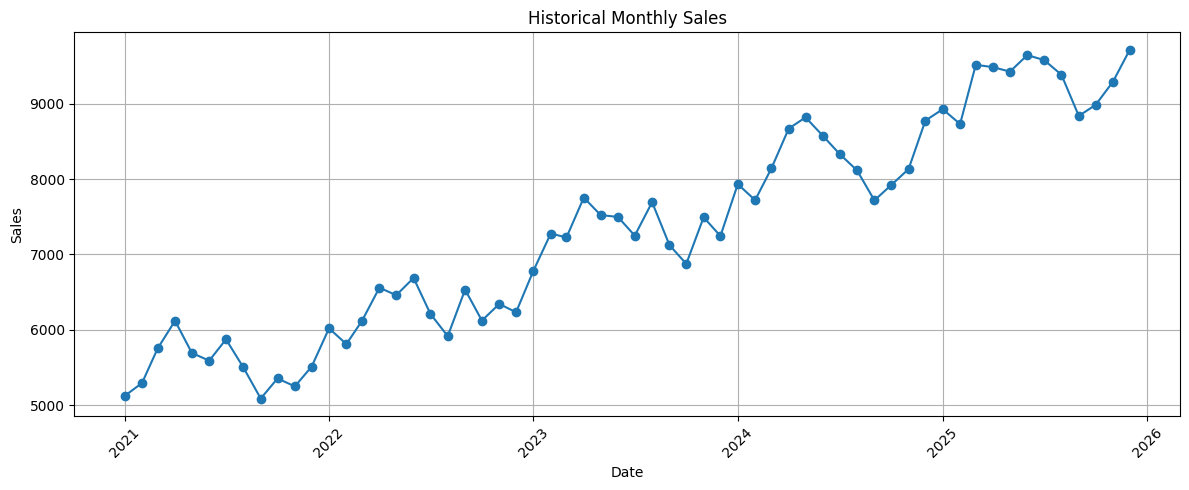

In [7]:

# Step 5: Plot historical sales

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Sales"], marker="o")

plt.title("Historical Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:

# Step 6: Create features

df["Month_Index"] = np.arange(len(df))

X = df[["Month_Index"]]
y = df["Sales"]

print("Input features (X):")
print(X.head())

print("\nTarget values (y):")
print(y.head())


Input features (X):
   Month_Index
0            0
1            1
2            2
3            3
4            4

Target values (y):
0    5124.178538
1    5295.433925
2    5754.934836
3    6120.757464
4    5694.474358
Name: Sales, dtype: float64


In [9]:

# Step 7: Split data chronologically

test_months = 12

train = df.iloc[:-test_months].copy()
test = df.iloc[-test_months:].copy()

X_train = train[["Month_Index"]]
y_train = train["Sales"]

X_test = test[["Month_Index"]]
y_test = test["Sales"]

print("Training records:", len(train))
print("Testing records:", len(test))


Training records: 48
Testing records: 12


In [10]:

# Step 8: Train Linear Regression model

model = LinearRegression()

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

print("Model coefficient:", model.coef_[0])
print("Model intercept:", model.intercept_)


Machine Learning model trained successfully!
Model coefficient: 72.4802436474459
Model intercept: 5125.38993367558


In [11]:

# Step 9: Predict sales for the test period

y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R² Score: {r2:.3f}")


MODEL EVALUATION
----------------
MAE  : 399.00
RMSE : 458.63
R² Score: -1.023


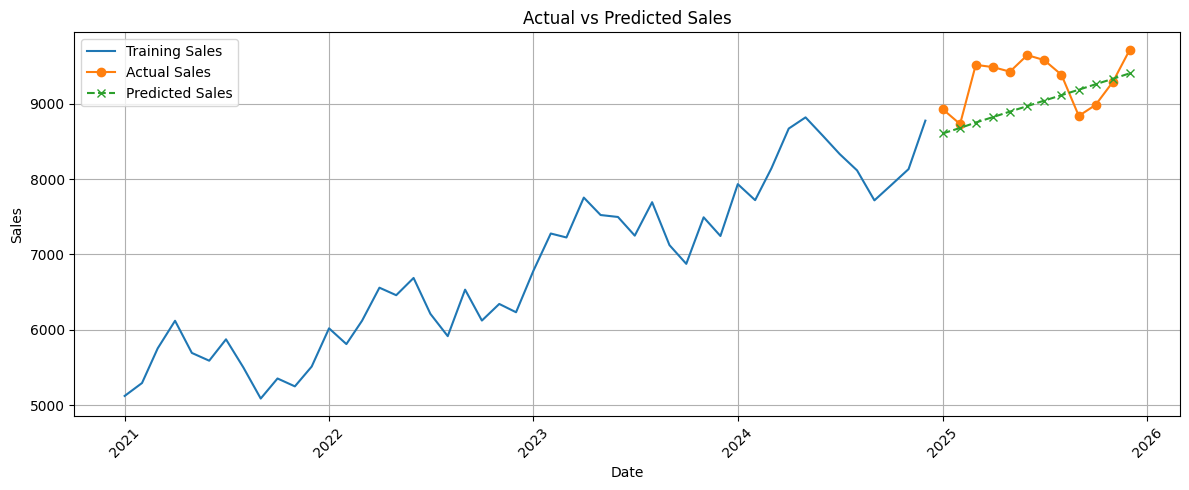

In [12]:

# Step 10: Visualize actual vs predicted sales

plt.figure(figsize=(12, 5))

plt.plot(
    train["Date"], train["Sales"],
    label="Training Sales"
)

plt.plot(
    test["Date"], y_test,
    marker="o", label="Actual Sales"
)

plt.plot(
    test["Date"], y_pred,
    marker="x", linestyle="--",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# Step 11: Forecast future sales

last_index = int(df["Month_Index"].max())

future_dates = pd.date_range(
    start=df["Date"].max() + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_data = pd.DataFrame({
    "Date": future_dates,
    "Month_Index": np.arange(
        last_index + 1,
        last_index + 13
    )
})

future_data["Predicted_Sales"] = model.predict(
    future_data[["Month_Index"]]
)

print("NEXT 12 MONTHS SALES FORECAST")
print(future_data.round(2))


NEXT 12 MONTHS SALES FORECAST
         Date  Month_Index  Predicted_Sales
0  2026-01-01           60          9474.20
1  2026-02-01           61          9546.68
2  2026-03-01           62          9619.17
3  2026-04-01           63          9691.65
4  2026-05-01           64          9764.13
5  2026-06-01           65          9836.61
6  2026-07-01           66          9909.09
7  2026-08-01           67          9981.57
8  2026-09-01           68         10054.05
9  2026-10-01           69         10126.53
10 2026-11-01           70         10199.01
11 2026-12-01           71         10271.49


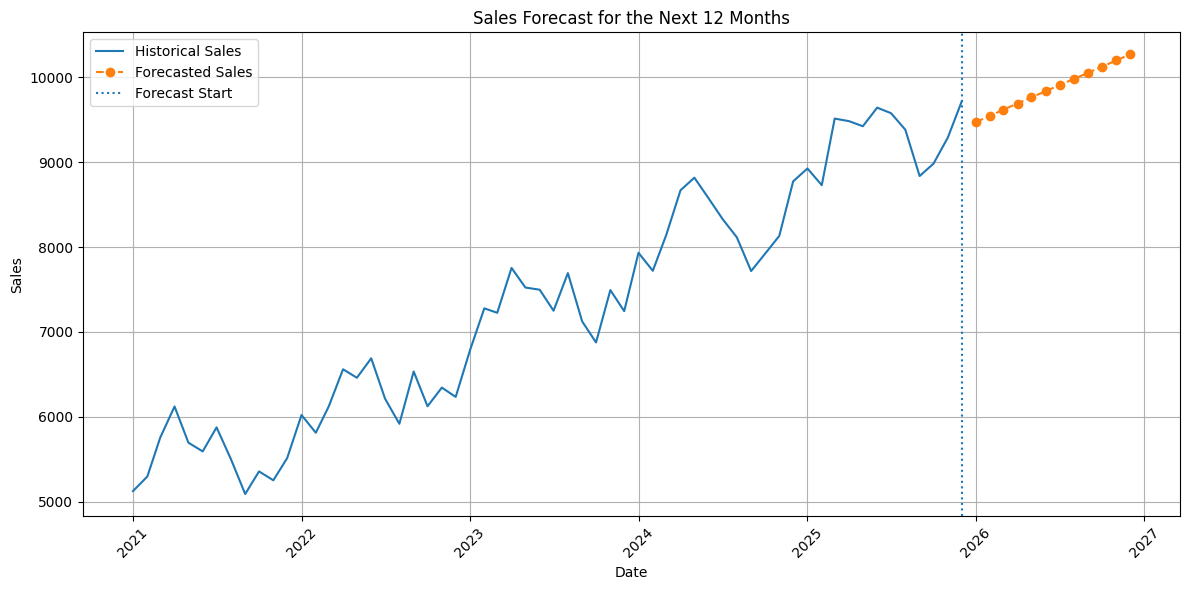

In [14]:

# Step 12: Plot historical and future sales

plt.figure(figsize=(12, 6))

plt.plot(
    df["Date"], df["Sales"],
    label="Historical Sales"
)

plt.plot(
    future_data["Date"],
    future_data["Predicted_Sales"],
    marker="o",
    linestyle="--",
    label="Forecasted Sales"
)

plt.axvline(
    df["Date"].max(),
    linestyle=":",
    label="Forecast Start"
)

plt.title("Sales Forecast for the Next 12 Months")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

# Step 13: Save project results

df.to_csv("cleaned_historical_sales.csv", index=False)

test_results = test[["Date", "Sales"]].copy()
test_results["Predicted_Sales"] = y_pred
test_results.to_csv("model_test_predictions.csv", index=False)

future_data.to_csv("future_sales_forecast.csv", index=False)

print("All three CSV files saved successfully!")


All three CSV files saved successfully!


In [16]:

from google.colab import files

files.download("future_sales_forecast.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Predictive Analytics Using Historical Data

**Objective:** To build a Machine Learning model that analyzes historical sales data and forecasts future sales trends.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, and Scikit-learn.

**Methodology:**
1. Created and explored historical monthly sales data.
2. Cleaned the dataset and prepared date-based features.
3. Split the data chronologically into training and testing sets.
4. Trained a Linear Regression model.
5. Evaluated the model using MAE, RMSE, and R² score.
6. Visualized actual sales, predicted sales, and future forecasts.

**Conclusion:** The project demonstrates how Machine Learning can use historical data to identify trends and estimate future sales. The model's performance was evaluated using standard regression metrics. Forecasts can help businesses plan inventory, estimate demand, and support decision-making. For real-world use, the model should be validated using actual historical data and compared with more advanced forecasting methods.